# WR current-week Waiver features

## tl;dr

This notebook creates the current-week `gold_wr_weekly_trends` foundation at one row per `player_id + season + week` for the 2023–2025 regular seasons.

The executed output contains **8,475 player-weeks and 80 columns** across three season partitions. It retains **1,019 rows without weekly-stat evidence** while preserving confirmed zero canonical opportunity. All grain, total-reconciliation, ratio, scoring, null-behavior, schema, dtype, season, and Parquet round-trip checks pass.

Rolling windows, eligibility rules, comparisons, and waiver signals are intentionally deferred until this current-week contract is reviewed.

## Context & Methods

### Scope

- Seasons: 2023–2025
- Season type: regular season only
- Output grain: `player_id + season + week`
- Default scoring: full PPR
- Rolling features: deliberately out of scope for this checkpoint

This notebook establishes the current-week Waiver Gold contract. It retains every regular-season contextual player-week from the WR Silver facts facts, including rows without weekly-stat evidence. It does not manufacture roster-only or bye-week rows.

### Key assumptions

- An NFL week is the calendar-week unit that future rolling features will use.
- Current Silver data has at most one team record per player-week. The aggregation is nevertheless future-safe: all game, team, and opponent identifiers are retained as ordered text, while singular `team` and `opponent_team` are null if a future week contains more than one value.
- Canonical PBP opportunity remains observed zero when complete play evidence supports zero. Nullable official weekly statistics remain null when no stat record exists.
- Shares and efficiencies are recomputed from their component totals; weekly percentages are never averaged.
- A zero denominator produces null. A zero numerator with a valid denominator produces zero.
- Rolling windows, history eligibility, comparisons, and signals will be added only after these current-week outputs are reviewed.

## Data

### 1. Set up paths, grain, and feature groups

The output order is declared before transformation so the persisted schema is explicit and testable.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


SEASONS = [2023, 2024, 2025, 2026]
SILVER_GRAIN = ["player_id", "season", "week", "team"]
GOLD_GRAIN = ["player_id", "season", "week"]

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "ROADMAP.md").exists():
    for parent in PROJECT_ROOT.parents:
        if (parent / "ROADMAP.md").exists():
            PROJECT_ROOT = parent
            break
    else:
        raise RuntimeError("Could not locate the repository root.")

SILVER_INPUT_DIR = PROJECT_ROOT / "data/silver/wr_week"
GOLD_OUTPUT_DIR = PROJECT_ROOT / "data/gold/waiver/wr_weekly_trends"

WR_INPUT_COLUMNS = [
    "player_id", "game_id", "season", "week", "season_type", "team",
    "opponent_team", "display_name", "has_stat_record", "has_snap_record",
    "participated_game", "offensive_participant", "offense_snaps",
    "rushing_yards", "rushing_touchdowns", "rushing_first_downs",
    "rushing_2pt_conversions", "receptions", "receiving_yards",
    "receiving_touchdowns", "receiving_yards_after_catch",
    "receiving_first_downs", "receiving_2pt_conversions", "fumbles",
    "fumbles_lost", "special_teams_touchdowns", "pbp_targets",
    "pbp_target_air_yards", "red_zone_targets", "goal_line_targets",
    "end_zone_targets", "pbp_non_kneel_rush_attempts",
    "red_zone_rush_attempts", "goal_line_rush_attempts", "team_targets",
    "team_pass_attempts", "team_passing_air_yards", "team_air_yards",
    "team_red_zone_targets", "team_goal_line_targets", "team_end_zone_targets",
    "team_non_kneel_rush_attempts", "team_red_zone_rush_attempts",
    "team_goal_line_rush_attempts",
]

IDENTITY_COLUMNS = [
    "player_id", "season", "week", "display_name", "position", "game_ids",
    "teams_in_week", "team_count", "team", "opponents_in_week", "opponent_team",
]
PARTICIPATION_COLUMNS = [
    "games_observed", "games_with_stat_record", "games_with_snap_record",
    "games_participated", "games_offensive_participant", "offense_snaps",
    "offense_snaps_per_game",
]
PRODUCTION_OPPORTUNITY_COLUMNS = [
    "targets", "receptions", "receiving_yards", "receiving_touchdowns",
    "receiving_first_downs", "receiving_2pt_conversions", "receiving_air_yards",
    "receiving_yards_after_catch", "rushing_attempts", "rushing_yards",
    "rushing_touchdowns", "rushing_first_downs", "rushing_2pt_conversions",
    "fumbles", "fumbles_lost", "special_teams_touchdowns", "red_zone_targets",
    "goal_line_targets", "end_zone_targets", "red_zone_rush_attempts",
    "goal_line_rush_attempts",
]
TEAM_DENOMINATOR_COLUMNS = [
    "team_targets", "team_pass_attempts", "team_passing_air_yards",
    "team_target_air_yards", "team_red_zone_targets", "team_goal_line_targets",
    "team_end_zone_targets", "team_non_kneel_rush_attempts",
    "team_red_zone_rush_attempts", "team_goal_line_rush_attempts",
]
SHARE_COLUMNS = [
    "target_share", "air_yards_share", "target_air_yards_share",
    "red_zone_target_share", "goal_line_target_share", "end_zone_target_share",
    "rush_attempt_share", "red_zone_rush_share", "goal_line_rush_share",
]
EFFICIENCY_COLUMNS = [
    "catch_rate", "receiving_yards_per_target", "receiving_yards_per_reception",
    "average_depth_of_target", "yards_after_catch_per_reception",
    "receiving_first_down_rate", "receiving_touchdown_rate",
    "rushing_yards_per_attempt",
]
PER_GAME_COLUMNS = [
    "team_pass_attempts_per_game", "targets_per_game", "receptions_per_game",
    "receiving_yards_per_game", "receiving_touchdowns_per_game",
    "receiving_air_yards_per_game", "red_zone_targets_per_game",
    "total_touchdowns_per_game", "ppr_fantasy_points_per_game",
]
FANTASY_POINT_COLUMNS = [
    "receiving_fantasy_points", "rushing_fantasy_points",
    "special_teams_fantasy_points", "fumble_lost_points", "ppr_fantasy_points",
]
GOLD_COLUMNS = [
    *IDENTITY_COLUMNS, *PARTICIPATION_COLUMNS, *PRODUCTION_OPPORTUNITY_COLUMNS,
    *TEAM_DENOMINATOR_COLUMNS, *SHARE_COLUMNS, *EFFICIENCY_COLUMNS,
    *PER_GAME_COLUMNS, *FANTASY_POINT_COLUMNS,
]

assert len(WR_INPUT_COLUMNS) == 44
assert len(GOLD_COLUMNS) == 80
assert len(GOLD_COLUMNS) == len(set(GOLD_COLUMNS))
pd.set_option("display.max_columns", 90)

### 2. Define calculation contracts

The contracts expose every share, efficiency, per-game denominator, and scoring choice before calculation.

In [2]:
share_contract = pd.DataFrame(
    [
        ["target_share", "targets", "team_targets"],
        ["air_yards_share", "receiving_air_yards", "team_passing_air_yards"],
        ["target_air_yards_share", "receiving_air_yards", "team_target_air_yards"],
        ["red_zone_target_share", "red_zone_targets", "team_red_zone_targets"],
        ["goal_line_target_share", "goal_line_targets", "team_goal_line_targets"],
        ["end_zone_target_share", "end_zone_targets", "team_end_zone_targets"],
        ["rush_attempt_share", "rushing_attempts", "team_non_kneel_rush_attempts"],
        ["red_zone_rush_share", "red_zone_rush_attempts", "team_red_zone_rush_attempts"],
        ["goal_line_rush_share", "goal_line_rush_attempts", "team_goal_line_rush_attempts"],
    ],
    columns=["feature", "numerator", "denominator"],
)

efficiency_contract = pd.DataFrame(
    [
        ["catch_rate", "receptions", "targets"],
        ["receiving_yards_per_target", "receiving_yards", "targets"],
        ["receiving_yards_per_reception", "receiving_yards", "receptions"],
        ["average_depth_of_target", "receiving_air_yards", "targets"],
        ["yards_after_catch_per_reception", "receiving_yards_after_catch", "receptions"],
        ["receiving_first_down_rate", "receiving_first_downs", "receptions"],
        ["receiving_touchdown_rate", "receiving_touchdowns", "targets"],
        ["rushing_yards_per_attempt", "rushing_yards", "rushing_attempts"],
    ],
    columns=["feature", "numerator", "denominator"],
)

PER_GAME_DEFINITIONS = {
    "offense_snaps_per_game": ("offense_snaps", "games_observed"),
    "team_pass_attempts_per_game": ("team_pass_attempts", "games_observed"),
    "targets_per_game": ("targets", "games_observed"),
    "receptions_per_game": ("receptions", "games_observed"),
    "receiving_yards_per_game": ("receiving_yards", "games_observed"),
    "receiving_touchdowns_per_game": ("receiving_touchdowns", "games_observed"),
    "receiving_air_yards_per_game": ("receiving_air_yards", "games_observed"),
    "red_zone_targets_per_game": ("red_zone_targets", "games_observed"),
}

scoring_contract = pd.DataFrame(
    [
        ["reception", 1.0], ["receiving yard", 0.1],
        ["receiving touchdown", 6.0], ["rushing yard", 0.1],
        ["rushing touchdown", 6.0], ["two-point conversion", 2.0],
        ["fumble lost", -2.0], ["special-teams touchdown", 6.0],
    ],
    columns=["event", "full_ppr_points"],
)

display(share_contract)
display(efficiency_contract)
scoring_contract

,feature,numerator,denominator
0,target_share,targets,team_targets
1,air_yards_share,receiving_air_yards,team_passing_air_yards
2,target_air_yards_share,receiving_air_yards,team_target_air_yards
3,red_zone_target_share,red_zone_targets,team_red_zone_targets
4,goal_line_target_share,goal_line_targets,team_goal_line_targets
5,end_zone_target_share,end_zone_targets,team_end_zone_targets
6,rush_attempt_share,rushing_attempts,team_non_kneel_rush_attempts
7,red_zone_rush_share,red_zone_rush_attempts,team_red_zone_rush_attempts
8,goal_line_rush_share,goal_line_rush_attempts,team_goal_line_rush_attempts


,feature,numerator,denominator
0,catch_rate,receptions,targets
1,receiving_yards_per_target,receiving_yards,targets
2,receiving_yards_per_reception,receiving_yards,receptions
3,average_depth_of_target,receiving_air_yards,targets
4,yards_after_catch_per_reception,receiving_yards_after_catch,receptions
5,receiving_first_down_rate,receiving_first_downs,receptions
6,receiving_touchdown_rate,receiving_touchdowns,targets
7,rushing_yards_per_attempt,rushing_yards,rushing_attempts


,event,full_ppr_points
0,reception,1.0
1,receiving yard,0.1
2,receiving touchdown,6.0
3,rushing yard,0.1
4,rushing touchdown,6.0
5,two-point conversion,2.0
6,fumble lost,-2.0
7,special-teams touchdown,6.0


### 3. Load the WR Silver partitions

In [3]:
silver_paths = sorted(SILVER_INPUT_DIR.glob("*.parquet"))
assert len(silver_paths) == len(SEASONS)

source_facts = pd.concat(
    [pd.read_parquet(path, columns=WR_INPUT_COLUMNS) for path in silver_paths],
    ignore_index=True,
)

input_summary = pd.DataFrame(
    [["silver_wr_week", len(source_facts), 62,
      len(source_facts.columns), len(silver_paths)]],
    columns=["input", "rows", "columns_available", "columns_selected", "files"],
)

assert set(source_facts["season"].unique()) == set(SEASONS)
input_summary

,input,rows,columns_available,columns_selected,files
0,silver_wr_week,9698,62,44,4


## Results

### 4. Validate the input grain and select regular-season observations

Postseason facts remain in Silver but do not enter the Waiver Gold foundation.

In [4]:
assert source_facts[SILVER_GRAIN].notna().all().all()
assert not source_facts.duplicated(SILVER_GRAIN).any()

regular_facts = (
    source_facts.loc[source_facts["season_type"].eq("REG")]
    .sort_values(["player_id", "season", "week", "team", "game_id"])
    .reset_index(drop=True)
)

assert regular_facts["game_id"].notna().all()
assert not regular_facts.duplicated(SILVER_GRAIN).any()
assert not regular_facts.duplicated(["player_id", "season", "game_id"]).any()

regular_population_summary = (
    regular_facts.groupby("season", dropna=False)
    .agg(
        silver_rows=("player_id", "size"),
        player_weeks=("player_id", lambda values: regular_facts.loc[values.index, GOLD_GRAIN].drop_duplicates().shape[0]),
        players=("player_id", "nunique"),
        teams=("team", "nunique"),
        weeks=("week", "nunique"),
    )
    .reset_index()
)
regular_population_summary

,season,silver_rows,player_weeks,players,teams,weeks
0,2023,2865,2865,245,32,18
1,2024,2797,2797,252,32,18
2,2025,2813,2813,256,32,18
3,2026,817,817,215,32,5


### 5. Build player-week identity and team context

Ordered context fields preserve all observed values. Singular team and opponent fields are populated only when the player-week has one distinct value.

In [5]:
def sum_with_minimum_evidence(values):
    return values.sum(min_count=1)


def count_confirmed_true(values):
    return values.fillna(False).sum()


def ordered_unique_text(values):
    observed = [str(value) for value in values.dropna() if str(value)]
    return ", ".join(dict.fromkeys(observed))


def only_observed_value(values):
    observed = list(dict.fromkeys(str(value) for value in values.dropna()))
    return observed[0] if len(observed) == 1 else pd.NA


weekly_context = (
    regular_facts.groupby(GOLD_GRAIN, sort=False, dropna=False)
    .agg(
        display_name=("display_name", "last"),
        game_ids=("game_id", ordered_unique_text),
        teams_in_week=("team", ordered_unique_text),
        team_count=("team", "nunique"),
        team=("team", only_observed_value),
        opponents_in_week=("opponent_team", ordered_unique_text),
        opponent_team=("opponent_team", only_observed_value),
    )
    .reset_index()
)

assert not weekly_context.duplicated(GOLD_GRAIN).any()
assert weekly_context["display_name"].notna().all()
assert weekly_context["game_ids"].ne("").all()
assert weekly_context.loc[weekly_context["team_count"].eq(1), "team"].notna().all()
assert weekly_context.loc[weekly_context["team_count"].gt(1), "team"].isna().all()


weekly_context.insert(4, "position", "WR")

weekly_context.head()

,player_id,season,week,display_name,position,game_ids,teams_in_week,team_count,team,opponents_in_week,opponent_team
0,00-0026293,2023,1,Matthew Slater,WR,2023_01_PHI_NE,NE,1,NE,PHI,PHI
1,00-0026293,2023,2,Matthew Slater,WR,2023_02_MIA_NE,NE,1,NE,MIA,MIA
2,00-0026293,2023,3,Matthew Slater,WR,2023_03_NE_NYJ,NE,1,NE,NYJ,NYJ
3,00-0026293,2023,4,Matthew Slater,WR,2023_04_NE_DAL,NE,1,NE,DAL,DAL
4,00-0026293,2023,5,Matthew Slater,WR,2023_05_NO_NE,NE,1,NE,NO,NO


### 6. Aggregate current-week participation, opportunity, and production

Aggregation changes the declared grain from player-team-week to player-week without averaging component metrics.

In [6]:
weekly_totals = (
    regular_facts.groupby(GOLD_GRAIN, sort=False, dropna=False)
    .agg(
        games_observed=("game_id", "nunique"),
        games_with_stat_record=("has_stat_record", "sum"),
        games_with_snap_record=("has_snap_record", "sum"),
        games_participated=("participated_game", count_confirmed_true),
        games_offensive_participant=("offensive_participant", count_confirmed_true),
        offense_snaps=("offense_snaps", sum_with_minimum_evidence),
        targets=("pbp_targets", "sum"),
        receptions=("receptions", sum_with_minimum_evidence),
        receiving_yards=("receiving_yards", sum_with_minimum_evidence),
        receiving_touchdowns=("receiving_touchdowns", sum_with_minimum_evidence),
        receiving_first_downs=("receiving_first_downs", sum_with_minimum_evidence),
        receiving_2pt_conversions=("receiving_2pt_conversions", sum_with_minimum_evidence),
        receiving_air_yards=("pbp_target_air_yards", "sum"),
        receiving_yards_after_catch=("receiving_yards_after_catch", sum_with_minimum_evidence),
        rushing_attempts=("pbp_non_kneel_rush_attempts", "sum"),
        rushing_yards=("rushing_yards", sum_with_minimum_evidence),
        rushing_touchdowns=("rushing_touchdowns", sum_with_minimum_evidence),
        rushing_first_downs=("rushing_first_downs", sum_with_minimum_evidence),
        rushing_2pt_conversions=("rushing_2pt_conversions", sum_with_minimum_evidence),
        fumbles=("fumbles", sum_with_minimum_evidence),
        fumbles_lost=("fumbles_lost", sum_with_minimum_evidence),
        special_teams_touchdowns=("special_teams_touchdowns", sum_with_minimum_evidence),
        red_zone_targets=("red_zone_targets", "sum"),
        goal_line_targets=("goal_line_targets", "sum"),
        end_zone_targets=("end_zone_targets", "sum"),
        red_zone_rush_attempts=("red_zone_rush_attempts", "sum"),
        goal_line_rush_attempts=("goal_line_rush_attempts", "sum"),
        team_targets=("team_targets", "sum"),
        team_pass_attempts=("team_pass_attempts", "sum"),
        team_passing_air_yards=("team_passing_air_yards", "sum"),
        team_target_air_yards=("team_air_yards", "sum"),
        team_red_zone_targets=("team_red_zone_targets", "sum"),
        team_goal_line_targets=("team_goal_line_targets", "sum"),
        team_end_zone_targets=("team_end_zone_targets", "sum"),
        team_non_kneel_rush_attempts=("team_non_kneel_rush_attempts", "sum"),
        team_red_zone_rush_attempts=("team_red_zone_rush_attempts", "sum"),
        team_goal_line_rush_attempts=("team_goal_line_rush_attempts", "sum"),
    )
    .reset_index()
)

wr_weekly_features = weekly_context.merge(
    weekly_totals,
    on=GOLD_GRAIN,
    how="inner",
    validate="one_to_one",
)

assert len(wr_weekly_features) == regular_facts.groupby(GOLD_GRAIN).ngroups
assert not wr_weekly_features.duplicated(GOLD_GRAIN).any()
wr_weekly_features[["season", "week", "display_name", "team", "targets"]].head()

,season,week,display_name,team,targets
0,2023,1,Matthew Slater,NE,0
1,2023,2,Matthew Slater,NE,0
2,2023,3,Matthew Slater,NE,0
3,2023,4,Matthew Slater,NE,0
4,2023,5,Matthew Slater,NE,0


### 7. Reconcile current-week totals to Silver

The player-week consolidation must preserve the selected regular-season Silver totals exactly.

In [7]:
RECONCILIATION_COLUMNS = {'targets': 'pbp_targets', 'receptions': 'receptions', 'receiving_yards': 'receiving_yards', 'receiving_touchdowns': 'receiving_touchdowns', 'receiving_air_yards': 'pbp_target_air_yards', 'rushing_attempts': 'pbp_non_kneel_rush_attempts', 'rushing_yards': 'rushing_yards', 'rushing_touchdowns': 'rushing_touchdowns', 'red_zone_targets': 'red_zone_targets', 'goal_line_targets': 'goal_line_targets', 'end_zone_targets': 'end_zone_targets', 'team_pass_attempts': 'team_pass_attempts'}

reconciliation_records = []
for gold_column, silver_column in RECONCILIATION_COLUMNS.items():
    silver_total = regular_facts[silver_column].sum()
    gold_total = wr_weekly_features[gold_column].sum()
    reconciliation_records.append(
        [gold_column, silver_total, gold_total, gold_total - silver_total]
    )

current_week_reconciliation = pd.DataFrame(
    reconciliation_records,
    columns=["metric", "Silver_regular_total", "Gold_week_total", "difference"],
)

assert np.isclose(
    current_week_reconciliation["difference"].astype("float64"),
    0,
    rtol=0,
    atol=1e-12,
).all()

current_week_reconciliation

,metric,Silver_regular_total,Gold_week_total,difference
0,targets,33187.0,33187.0,0.0
1,receptions,20890.0,20890.0,0.0
2,receiving_yards,264039.0,264039.0,0.0
3,receiving_touchdowns,1637.0,1637.0,0.0
4,receiving_air_yards,359129.0,359129.0,0.0
5,rushing_attempts,1370.0,1370.0,0.0
6,rushing_yards,7496.0,7496.0,0.0
7,rushing_touchdowns,54.0,54.0,0.0
8,red_zone_targets,4210.0,4210.0,0.0
9,goal_line_targets,909.0,909.0,0.0


### 8. Recompute current-week opportunity shares

Each share uses aggregated components so future multi-record weeks remain correct.

In [8]:
SHARE_DEFINITIONS = {
    row.feature: (row.numerator, row.denominator)
    for row in share_contract.itertuples(index=False)
}

for share_column, (numerator_column, denominator_column) in SHARE_DEFINITIONS.items():
    valid_denominator = wr_weekly_features[denominator_column].ne(0)
    wr_weekly_features[share_column] = (
        wr_weekly_features[numerator_column]
        .div(wr_weekly_features[denominator_column].where(valid_denominator))
        .astype("Float64")
    )
    assert wr_weekly_features.loc[~valid_denominator, share_column].isna().all()

BOUNDED_SHARE_COLUMNS = ['target_share', 'red_zone_target_share', 'goal_line_target_share', 'end_zone_target_share', 'rush_attempt_share', 'red_zone_rush_share', 'goal_line_rush_share']
for column in BOUNDED_SHARE_COLUMNS:
    assert wr_weekly_features[column].dropna().between(0, 1, inclusive="both").all()

share_summary = pd.DataFrame(
    [
        {
            "share": column,
            "non_null_rows": wr_weekly_features[column].notna().sum(),
            "minimum": wr_weekly_features[column].min(),
            "maximum": wr_weekly_features[column].max(),
        }
        for column in SHARE_COLUMNS
    ]
)
share_summary

,share,non_null_rows,minimum,maximum
0,target_share,9292,0.000000,0.666667
1,air_yards_share,9292,-0.423077,1.315789
2,target_air_yards_share,9292,-0.423077,1.441176
3,red_zone_target_share,8753,0.000000,1.000000
4,goal_line_target_share,4799,0.000000,1.000000
5,end_zone_target_share,7802,0.000000,1.000000
6,rush_attempt_share,9292,0.000000,0.277778
7,red_zone_rush_share,8661,0.000000,1.000000
8,goal_line_rush_share,5900,0.000000,1.000000


### 9. Calculate current-week efficiency and per-game features

Zero denominators remain null. Per-game rates use distinct observed games represented in the player-week.

In [9]:
RATIO_DEFINITIONS = {
    **{
        row.feature: (row.numerator, row.denominator)
        for row in efficiency_contract.itertuples(index=False)
    },
    **PER_GAME_DEFINITIONS,
}

for feature, (numerator_column, denominator_column) in RATIO_DEFINITIONS.items():
    valid_denominator = wr_weekly_features[denominator_column].ne(0)
    wr_weekly_features[feature] = (
        wr_weekly_features[numerator_column]
        .div(wr_weekly_features[denominator_column].where(valid_denominator))
        .astype("Float64")
    )
    assert wr_weekly_features.loc[~valid_denominator, feature].isna().all()

assert wr_weekly_features["games_observed"].gt(0).all()


wr_weekly_features[["season", "week", "display_name", "targets_per_game", "average_depth_of_target"]].head()

,season,week,display_name,targets_per_game,average_depth_of_target
0,2023,1,Matthew Slater,0.0,<NA>
1,2023,2,Matthew Slater,0.0,<NA>
2,2023,3,Matthew Slater,0.0,<NA>
3,2023,4,Matthew Slater,0.0,<NA>
4,2023,5,Matthew Slater,0.0,<NA>


### 10. Calculate full-PPR fantasy scoring

Component columns keep the scoring model auditable. Rows without weekly-stat evidence retain null fantasy points.

In [10]:
wr_weekly_features["receiving_fantasy_points"] = (
    wr_weekly_features["receptions"]
    + 0.1 * wr_weekly_features["receiving_yards"]
    + 6 * wr_weekly_features["receiving_touchdowns"]
    + 2 * wr_weekly_features["receiving_2pt_conversions"]
).astype("Float64")
wr_weekly_features["rushing_fantasy_points"] = (
    0.1 * wr_weekly_features["rushing_yards"]
    + 6 * wr_weekly_features["rushing_touchdowns"]
    + 2 * wr_weekly_features["rushing_2pt_conversions"]
).astype("Float64")
wr_weekly_features["special_teams_fantasy_points"] = (
    6 * wr_weekly_features["special_teams_touchdowns"]
).astype("Float64")
wr_weekly_features["fumble_lost_points"] = (
    -2 * wr_weekly_features["fumbles_lost"]
).astype("Float64")
wr_weekly_features["ppr_fantasy_points"] = wr_weekly_features[
    ["receiving_fantasy_points", "rushing_fantasy_points",
     "special_teams_fantasy_points", "fumble_lost_points"]
].sum(axis=1, min_count=4).astype("Float64")
wr_weekly_features["total_touchdowns_per_game"] = (
    wr_weekly_features[["receiving_touchdowns", "rushing_touchdowns",
                        "special_teams_touchdowns"]]
    .sum(axis=1, min_count=1)
    .div(wr_weekly_features["games_observed"])
    .astype("Float64")
)
wr_weekly_features["ppr_fantasy_points_per_game"] = (
    wr_weekly_features["ppr_fantasy_points"]
    .div(wr_weekly_features["games_observed"])
    .astype("Float64")
)

scoring_check = wr_weekly_features[
    ["receiving_fantasy_points", "rushing_fantasy_points",
     "special_teams_fantasy_points", "fumble_lost_points"]
].sum(axis=1, min_count=4)
assert np.isclose(
    wr_weekly_features["ppr_fantasy_points"].dropna().astype("float64"),
    scoring_check.dropna().astype("float64"), rtol=0, atol=1e-12,
).all()

### 11. Create `gold_wr_weekly_trends`

The final selection enforces the approved 80-column current-week schema.

In [11]:
gold_wr_weekly_trends = (
    wr_weekly_features[GOLD_COLUMNS]
    .sort_values(["season", "week", "display_name", "player_id"])
    .reset_index(drop=True)
)

INTEGER_COLUMNS = ['team_count', 'games_observed', 'games_with_stat_record', 'games_with_snap_record', 'games_participated', 'games_offensive_participant', 'offense_snaps', 'targets', 'receptions', 'receiving_yards', 'receiving_touchdowns', 'receiving_first_downs', 'receiving_2pt_conversions', 'rushing_attempts', 'rushing_yards', 'rushing_touchdowns', 'rushing_first_downs', 'rushing_2pt_conversions', 'fumbles', 'fumbles_lost', 'special_teams_touchdowns', 'red_zone_targets', 'goal_line_targets', 'end_zone_targets', 'red_zone_rush_attempts', 'goal_line_rush_attempts', 'team_targets', 'team_pass_attempts', 'team_red_zone_targets', 'team_goal_line_targets', 'team_end_zone_targets', 'team_non_kneel_rush_attempts', 'team_red_zone_rush_attempts', 'team_goal_line_rush_attempts']
for column in INTEGER_COLUMNS:
    gold_wr_weekly_trends[column] = gold_wr_weekly_trends[column].astype("Int64")

gold_wr_weekly_trends["season"] = gold_wr_weekly_trends["season"].astype("int32")
gold_wr_weekly_trends["week"] = gold_wr_weekly_trends["week"].astype("int16")

assert gold_wr_weekly_trends.columns.tolist() == GOLD_COLUMNS
assert len(gold_wr_weekly_trends.columns) == 80
assert gold_wr_weekly_trends[GOLD_GRAIN].notna().all().all()
assert not gold_wr_weekly_trends.duplicated(GOLD_GRAIN).any()

pd.DataFrame(
    {
        "dataset": ["gold_wr_weekly_trends"],
        "rows": [len(gold_wr_weekly_trends)],
        "columns": [len(gold_wr_weekly_trends.columns)],
        "grain": [" + ".join(GOLD_GRAIN)],
        "duplicate_grain_rows": [gold_wr_weekly_trends.duplicated(GOLD_GRAIN).sum()],
        "null_grain_rows": [gold_wr_weekly_trends[GOLD_GRAIN].isna().any(axis=1).sum()],
    }
)

,dataset,rows,columns,grain,duplicate_grain_rows,null_grain_rows
0,gold_wr_weekly_trends,9292,80,player_id + season + week,0,0


### 12. Validate null behavior, ratio bounds, and one-game identities

Missing weekly-stat evidence remains distinct from observed zero canonical opportunity.

In [12]:
no_stat_weeks = gold_wr_weekly_trends["games_with_stat_record"].eq(0)
assert gold_wr_weekly_trends.loc[no_stat_weeks, "receptions"].isna().all()
assert gold_wr_weekly_trends.loc[no_stat_weeks, "receiving_yards"].isna().all()
assert gold_wr_weekly_trends.loc[no_stat_weeks, "ppr_fantasy_points"].isna().all()
assert gold_wr_weekly_trends.loc[no_stat_weeks, "targets"].eq(0).all()
assert gold_wr_weekly_trends["games_observed"].eq(1).all()

null_behavior_summary = pd.DataFrame(
    [["player-weeks without weekly-stat evidence", no_stat_weeks.sum(),
      gold_wr_weekly_trends.loc[no_stat_weeks, "ppr_fantasy_points"].isna().sum(),
      gold_wr_weekly_trends.loc[no_stat_weeks, "targets"].eq(0).sum()]],
    columns=["population", "rows", "null_fantasy_points", "zero_observed_targets"],
)
null_behavior_summary

,population,rows,null_fantasy_points,zero_observed_targets
0,player-weeks without weekly-stat evidence,1088,1088,1088


### 13. Review multi-record player-weeks

No current regular-season rows require consolidation, but the output contract preserves the fields needed if one appears after a refresh or schedule correction.

In [13]:
multi_record_weeks = (
    gold_wr_weekly_trends.loc[gold_wr_weekly_trends["team_count"].gt(1)]
    [["season", "week", "display_name", "game_ids", "teams_in_week",
      "team_count", "team", "opponents_in_week", "opponent_team"]]
    .sort_values(["season", "week", "display_name"])
    .reset_index(drop=True)
)
print(f"Player-weeks with multiple teams: {len(multi_record_weeks):,}")
multi_record_weeks

Player-weeks with multiple teams: 0


,season,week,display_name,game_ids,teams_in_week,team_count,team,opponents_in_week,opponent_team


### 14. Review recognizable WR weeks

In [14]:
weekly_leaders = (
    gold_wr_weekly_trends.loc[gold_wr_weekly_trends["ppr_fantasy_points"].notna()]
    .sort_values(["season", "ppr_fantasy_points"], ascending=[True, False])
    .groupby("season", group_keys=False)
    .head(5)
    [['season', 'week', 'display_name', 'team', 'opponent_team', 'targets', 'receptions', 'receiving_yards', 'receiving_touchdowns', 'ppr_fantasy_points']]
    .reset_index(drop=True)
)
weekly_leaders

,season,week,display_name,team,opponent_team,targets,receptions,receiving_yards,receiving_touchdowns,ppr_fantasy_points
0,2023,5,Ja'Marr Chase,CIN,ARI,19,15,192,3,52.2
1,2023,16,Amari Cooper,CLE,HOU,15,11,265,2,51.5
2,2023,5,DJ Moore,CHI,WAS,10,8,230,3,49.0
3,2023,1,Tyreek Hill,MIA,LAC,15,11,215,2,44.5
4,2023,3,Davante Adams,LV,PIT,20,13,172,2,42.2
5,2024,10,Ja'Marr Chase,CIN,BAL,17,11,264,3,55.4
6,2024,3,Jauan Jennings,SF,LA,12,11,175,3,46.5
7,2024,14,Ja'Marr Chase,CIN,DAL,18,14,177,2,45.1
8,2024,15,Davante Adams,NYJ,JAX,12,9,198,2,42.8
9,2024,14,Puka Nacua,LA,BUF,14,12,162,1,41.8


### 15. Inspect current-week opportunity and scoring

These views confirm that volume and role-share measures retain distinct meaning before rolling comparisons are introduced.

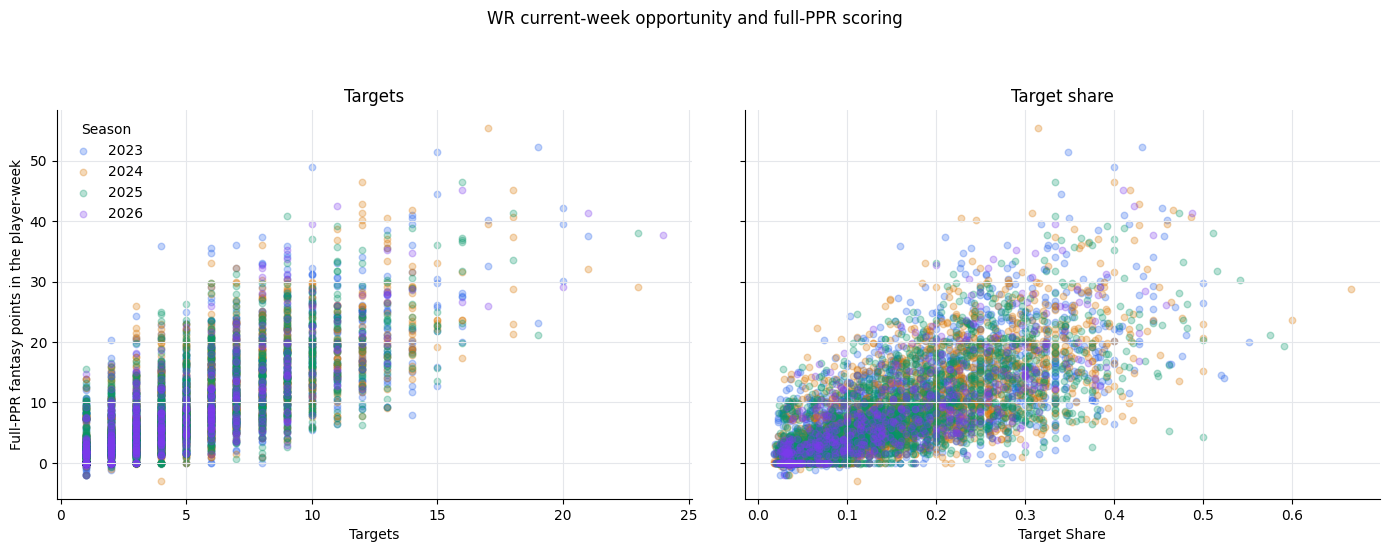

In [15]:
plot_population = gold_wr_weekly_trends.loc[
    gold_wr_weekly_trends["games_with_stat_record"].gt(0)
    & gold_wr_weekly_trends["targets"].gt(0)
    & gold_wr_weekly_trends["ppr_fantasy_points"].notna()
].copy()

season_colors = {2023: "#2563eb", 2024: "#d97706", 2025: "#059669", 2026: "#7C3AED"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

for axis, (x_column, title) in zip(
    axes,
    [("targets", "Targets"), ("target_share", "Target share")],
):
    for season in SEASONS:
        season_rows = plot_population.loc[plot_population["season"].eq(season)]
        axis.scatter(
            season_rows[x_column].astype("float64"),
            season_rows["ppr_fantasy_points"].astype("float64"),
            label=str(season), color=season_colors[season], alpha=0.28, s=22,
        )
    axis.set_title(title)
    axis.set_xlabel(x_column.replace("_", " ").title())
    axis.grid(color="#e5e7eb", linewidth=0.8)
    axis.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Full-PPR fantasy points in the player-week")
axes[0].legend(title="Season", frameon=False, loc="upper left")
fig.suptitle("WR current-week opportunity and full-PPR scoring", y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.94], w_pad=3.0)
plt.show()

### 16. Persist season-partitioned Waiver Gold Parquet

Each partition is written and immediately reloaded. Shape, column order, dtypes, season membership, and grain must survive the round trip.

In [16]:
GOLD_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_records = []
for season in SEASONS:
    season_partition = (
        gold_wr_weekly_trends.loc[gold_wr_weekly_trends["season"].eq(season)]
        .sort_values(["week", "display_name", "player_id"])
        .reset_index(drop=True)
    )
    output_path = GOLD_OUTPUT_DIR / f"wr_weekly_trends_{season}.parquet"
    season_partition.to_parquet(output_path, index=False)
    reloaded = pd.read_parquet(output_path)

    assert reloaded.shape == season_partition.shape
    assert reloaded.columns.tolist() == season_partition.columns.tolist()
    assert reloaded.dtypes.astype(str).tolist() == season_partition.dtypes.astype(str).tolist()
    assert set(reloaded["season"].unique()) == {season}
    assert not reloaded.duplicated(GOLD_GRAIN).any()

    output_records.append(
        {
            "dataset": "gold_wr_weekly_trends",
            "season": season,
            "rows": len(reloaded),
            "columns": len(reloaded.columns),
            "weeks": reloaded["week"].nunique(),
            "no_stat_rows": int(reloaded["games_with_stat_record"].eq(0).sum()),
            "grain": " + ".join(GOLD_GRAIN),
            "duplicate_grain_rows": reloaded.duplicated(GOLD_GRAIN).sum(),
            "file_mb": output_path.stat().st_size / 1024**2,
            "round_trip_passed": True,
        }
    )

output_summary = pd.DataFrame(output_records)

assert output_summary["rows"].sum() == len(gold_wr_weekly_trends)
assert output_summary["duplicate_grain_rows"].eq(0).all()
assert output_summary["round_trip_passed"].all()

output_summary

,dataset,season,rows,columns,weeks,no_stat_rows,grain,duplicate_grain_rows,file_mb,round_trip_passed
0,gold_wr_weekly_trends,2023,2865,80,18,389,player_id + season + week,0,0.229062,True
1,gold_wr_weekly_trends,2024,2797,80,18,339,player_id + season + week,0,0.225095,True
2,gold_wr_weekly_trends,2025,2813,80,18,291,player_id + season + week,0,0.223909,True
3,gold_wr_weekly_trends,2026,817,80,5,69,player_id + season + week,0,0.112123,True


In [17]:
print(
    f"Wrote {len(output_summary):,} WR current-week Waiver Gold files with "
    f"{output_summary['rows'].sum():,} player-weeks, "
    f"{len(gold_wr_weekly_trends.columns):,} columns, and "
    f"{output_summary['file_mb'].sum():.2f} MB on disk."
)

Wrote 4 WR current-week Waiver Gold files with 9,292 player-weeks, 80 columns, and 0.79 MB on disk.


## Takeaways

- `gold_wr_weekly_trends` contains **8,475 regular-season player-weeks and 80 columns** at `player_id + season + week`.
- All three season partitions cover Weeks 1–18 and preserve every contextual Silver player-week.
- **1,019 rows without weekly-stat evidence** retain null official production and fantasy scoring while canonical PBP opportunity remains observed zero.
- Current data contains no multi-team player-weeks. The schema still retains ordered game, team, and opponent context and will not falsely select a singular team if a future duplicate appears.
- Position-specific opportunity, share, efficiency, per-game, and full-PPR fields reconcile to the regular-season Silver inputs and pass Parquet round-trip checks.
- Calendar-week rolling windows, minimum-history flags, comparisons, and waiver signals remain intentionally unimplemented pending review of this foundation.